# One-Way Analysis of Variance (ANOVA)
---

# Experiment: reproduce the entire ANOVA table from first principles.

In [2]:
import numpy as np
from scipy import stats

groups = {
    "A": np.array([6, 8, 7, 9], dtype=float),
    "B": np.array([10, 12, 11, 13], dtype=float),
    "C": np.array([8, 10, 9, 11], dtype=float),
}
k = len(groups)
N = sum(len(x) for x in groups.values())
grand_mean = np.concatenate(list(groups.values())).mean()

ss_between = sum(len(x) * (x.mean() - grand_mean)**2
                 for x in groups.values())
ss_within = sum(np.sum((x - x.mean())**2)
                for x in groups.values())
ss_total = sum(np.sum((x - grand_mean)**2)
               for x in groups.values())
df_between, df_within = k - 1, N - k
ms_between = ss_between / df_between
ms_within = ss_within / df_within
F = ms_between / ms_within
p = stats.f.sf(F, df_between, df_within)
critical = stats.f.ppf(0.95, df_between, df_within)

for label, x in groups.items():
    print(f"{label}: n={len(x)}, mean={x.mean():.2f}, "
          f"variance={x.var(ddof=1):.4f}")
print(f"Grand mean = {grand_mean:.2f}")
print(f"SS_between={ss_between:.2f}, SS_within={ss_within:.2f}, "
      f"SS_total={ss_total:.2f}")
print(f"Degrees of freedom: {df_between}, {df_within}, {N-1}")
print(f"F={F:.4f}, p={p:.6f}, critical value={critical:.4f}")

library_result = stats.f_oneway(*groups.values())

print(library_result.statistic)
print(library_result.pvalue)

A: n=4, mean=7.50, variance=1.6667
B: n=4, mean=11.50, variance=1.6667
C: n=4, mean=9.50, variance=1.6667
Grand mean = 9.50
SS_between=32.00, SS_within=15.00, SS_total=47.00
Degrees of freedom: 2, 9, 11
F=9.6000, p=0.005861, critical value=4.2565
9.6
0.005860980885859728


##  Experiment: visualize between-group and within-group variation.

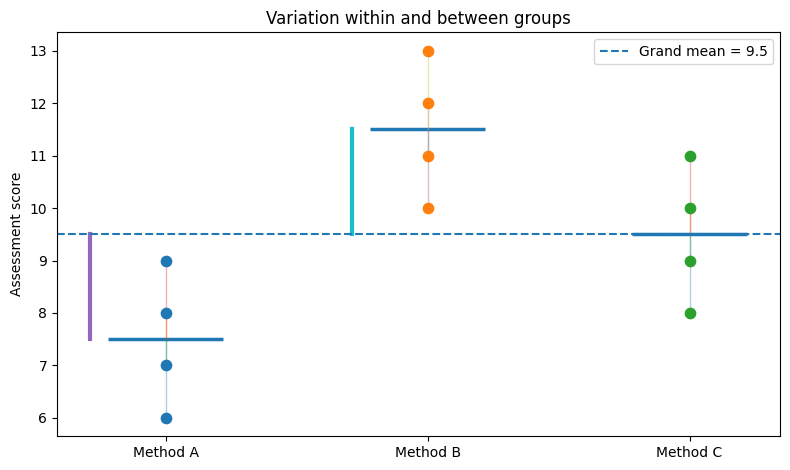

In [3]:
import numpy as np
import matplotlib.pyplot as plt

groups = [np.array([6, 8, 7, 9]),
          np.array([10, 12, 11, 13]),
          np.array([8, 10, 9, 11])]
names = ["Method A", "Method B", "Method C"]
grand = np.concatenate(groups).mean()

fig, ax = plt.subplots(figsize=(8, 4.8))
for i, x in enumerate(groups, start=1):
    m = x.mean()
    ax.scatter(np.full(len(x), i), x, s=55, zorder=3)
    ax.hlines(m, i - 0.22, i + 0.22, linewidth=2.5)
    for value in x:
        ax.plot([i, i], [m, value], alpha=0.35, linewidth=1)
    ax.plot([i - 0.29, i - 0.29], [grand, m], linewidth=3)
ax.axhline(grand, linestyle="--", linewidth=1.5,
           label=f"Grand mean = {grand:.1f}")
ax.set(xticks=range(1, 4), xticklabels=names,
       ylabel="Assessment score", title="Variation within and between groups")
ax.legend()
fig.tight_layout()
fig.savefig("../../images/anova_between_within.png", dpi=170, bbox_inches="tight")
plt.show()

## Experiment: simulate F-statistics under the null and under unequal means.

Estimated type-I error: 0.052
Estimated power for chosen means: 0.714


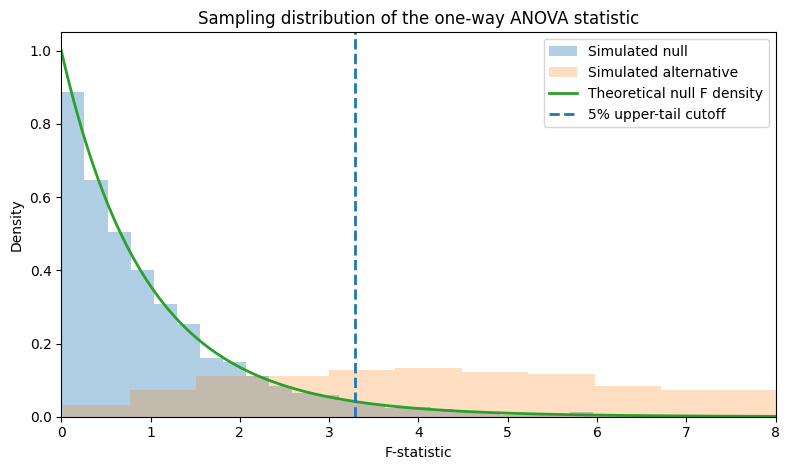

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

rng = np.random.default_rng(153)
n_reps, n_each = 4000, 12
k, N = 3, 3 * n_each

# Rows represent independent experiments; columns represent observations.
null_data = rng.normal(loc=0, scale=1, size=(n_reps, k, n_each))
alt_data = rng.normal(loc=np.array([0.0, 0.6, 1.2])[None, :, None],
                      scale=1, size=(n_reps, k, n_each))

def simulated_F(samples):
    group_means = samples.mean(axis=2)
    grand_means = samples.mean(axis=(1, 2))
    ssb = n_each * np.sum((group_means - grand_means[:, None])**2, axis=1)
    ssw = np.sum((samples - group_means[:, :, None])**2, axis=(1, 2))
    return (ssb / (k - 1)) / (ssw / (N - k))

f_null = simulated_F(null_data)
f_alt = simulated_F(alt_data)
cutoff = stats.f.ppf(0.95, k - 1, N - k)
print(f"Estimated type-I error: {np.mean(f_null > cutoff):.3f}")
print(f"Estimated power for chosen means: {np.mean(f_alt > cutoff):.3f}")

x = np.linspace(0, 8, 350)
fig, ax = plt.subplots(figsize=(8, 4.8))
ax.hist(f_null, bins=55, density=True, alpha=0.35, label="Simulated null")
ax.hist(f_alt, bins=55, density=True, alpha=0.25, label="Simulated alternative")
ax.plot(x, stats.f.pdf(x, k - 1, N - k), linewidth=2,
        label="Theoretical null F density")
ax.axvline(cutoff, linestyle="--", linewidth=2, label="5% upper-tail cutoff")
ax.set(xlim=(0, 8), xlabel="F-statistic", ylabel="Density",
       title="Sampling distribution of the one-way ANOVA statistic")
ax.legend()
fig.tight_layout()
fig.savefig("../../images/anova_null_alternative_f.png", dpi=170,
            bbox_inches="tight")
plt.show()

## Experiment: verify the identity F = t squared.

In [5]:
import numpy as np
from scipy import stats

A = np.array([6, 8, 7, 9], dtype=float)
B = np.array([10, 12, 11, 13], dtype=float)
t = stats.ttest_ind(A, B, equal_var=True)
f = stats.f_oneway(A, B)
print(f"t = {t.statistic:.6f}")
print(f"t^2 = {t.statistic**2:.6f}")
print(f"F = {f.statistic:.6f}")
print(f"Two-sided t-test p = {t.pvalue:.6f}")
print(f"ANOVA p = {f.pvalue:.6f}")

t = -4.381780
t^2 = 19.200000
F = 19.200000
Two-sided t-test p = 0.004659
ANOVA p = 0.004659


## Experiment: identify differing groups with Tukey's multiple-comparison procedure.

In [6]:
import numpy as np
from statsmodels.stats.multicomp import pairwise_tukeyhsd

A = np.array([6, 8, 7, 9], dtype=float)
B = np.array([10, 12, 11, 13], dtype=float)
C = np.array([8, 10, 9, 11], dtype=float)
values = np.concatenate([A, B, C])
labels = np.repeat(["A", "B", "C"], [len(A), len(B), len(C)])

result = pairwise_tukeyhsd(endog=values, groups=labels, alpha=0.05)
print(result.summary())

Multiple Comparison of Means - Tukey HSD, FWER=0.05
group1 group2 meandiff p-adj   lower  upper  reject
---------------------------------------------------
     A      B      4.0 0.0045  1.4513 6.5487   True
     A      C      2.0 0.1263 -0.5487 4.5487  False
     B      C     -2.0 0.1263 -4.5487 0.5487  False
---------------------------------------------------


## Experiment: calculate effect sizes and a prespecified contrast.

In [7]:
import numpy as np
from scipy import stats

groups = [np.array([6, 8, 7, 9], dtype=float),
          np.array([10, 12, 11, 13], dtype=float),
          np.array([8, 10, 9, 11], dtype=float)]
means = np.array([x.mean() for x in groups])
ns = np.array([len(x) for x in groups])
k, N = len(groups), sum(ns)
grand = np.concatenate(groups).mean()
ssb = sum(n * (m - grand)**2 for n, m in zip(ns, means))
ssw = sum(np.sum((x - x.mean())**2) for x in groups)
mse = ssw / (N - k)
eta2 = ssb / (ssb + ssw)
omega2 = (ssb - (k - 1) * mse) / (ssb + ssw + mse)

# Illustration of a contrast specified BEFORE inspecting the outcomes:
# "Method B minus Method A"; no post-hoc multiplicity claim is made.
contrast = np.array([-1., 1., 0.])
estimate = np.dot(contrast, means)
se = np.sqrt(mse * np.sum(contrast**2 / ns))
t_stat = estimate / se
df = N - k
p_two_sided = 2 * stats.t.sf(abs(t_stat), df)
ci = estimate + stats.t.ppf([0.025, 0.975], df) * se
print(f"eta^2 = {eta2:.4f}; omega^2 = {omega2:.4f}")
print(f"Prespecified B - A = {estimate:.3f}")
print(f"t({df}) = {t_stat:.3f}, unadjusted p = {p_two_sided:.4f}")
print(f"Unadjusted 95% CI = ({ci[0]:.3f}, {ci[1]:.3f})")

eta^2 = 0.6809; omega^2 = 0.5890
Prespecified B - A = 4.000
t(9) = 4.382, unadjusted p = 0.0018
Unadjusted 95% CI = (1.935, 6.065)


## Experiment: calculate Welch ANOVA by hand in Python and compare it with classical ANOVA.

In [8]:
import numpy as np
from scipy import stats
from statsmodels.stats.oneway import anova_oneway

groups = [np.array([48, 51, 50, 49, 52], dtype=float),
          np.array([45, 55, 60, 40, 50, 65], dtype=float),
          np.array([55, 58, 57, 56], dtype=float)]
k = len(groups)
ns = np.array([len(x) for x in groups], dtype=float)
means = np.array([x.mean() for x in groups])
variances = np.array([x.var(ddof=1) for x in groups])
weights = ns / variances
W = weights.sum()
weighted_mean = np.dot(weights, means) / W
T = np.sum((1 - weights / W)**2 / (ns - 1))
A = np.sum(weights * (means - weighted_mean)**2) / (k - 1)
F_welch = A / (1 + 2 * (k - 2) / (k**2 - 1) * T)
df_welch = (k**2 - 1) / (3 * T)
p_welch = stats.f.sf(F_welch, k - 1, df_welch)

library_welch = anova_oneway(groups, use_var="unequal")
ordinary = stats.f_oneway(*groups)
print("Means:", means)
print("Sample variances:", variances)
print(f"Welch F({k-1}, {df_welch:.4f}) = {F_welch:.4f}")
print(f"Welch p = {p_welch:.6f}")
print(f"Classical F = {ordinary.statistic:.4f}, p = {ordinary.pvalue:.6f}")
print(library_welch.statistic)
print(library_welch.pvalue)

Means: [50.  52.5 56.5]
Sample variances: [ 2.5        87.5         1.66666667]
Welch F(2, 7.8056) = 21.2661
Welch p = 0.000693
Classical F = 1.2522, p = 0.320705
21.266051846569507
0.0006929914211358148


## Experiment: calculate Games–Howell adjusted p-values and intervals.

In [9]:
import numpy as np
from scipy.stats import studentized_range
from itertools import combinations

groups = {
    "A": np.array([48, 51, 50, 49, 52], dtype=float),
    "B": np.array([45, 55, 60, 40, 50, 65], dtype=float),
    "C": np.array([55, 58, 57, 56], dtype=float),
}
k, alpha = len(groups), 0.05
for (name_i, x), (name_j, y) in combinations(groups.items(), 2):
    difference = x.mean() - y.mean()
    a = x.var(ddof=1) / len(x)
    b = y.var(ddof=1) / len(y)
    df = (a + b)**2 / (a*a/(len(x)-1) + b*b/(len(y)-1))
    se_q = np.sqrt((a + b) / 2)
    q = abs(difference) / se_q
    p_adjusted = studentized_range.sf(q, k, df)
    margin = studentized_range.ppf(1-alpha, k, df) * se_q
    lower, upper = difference - margin, difference + margin
    print(f"{name_i} - {name_j}: difference={difference:.2f}, "
          f"df={df:.2f}, adjusted p={p_adjusted:.5f}, "
          f"simultaneous CI=({lower:.2f}, {upper:.2f})")

A - B: difference=-2.50, df=5.34, adjusted p=0.80334, simultaneous CI=(-14.85, 9.85)
A - C: difference=-6.50, df=6.98, adjusted p=0.00065, simultaneous CI=(-9.32, -3.68)
B - C: difference=-4.00, df=5.28, adjusted p=0.58875, simultaneous CI=(-16.36, 8.36)


## Experiment: examine residuals, group spreads, and a robust variance diagnostic.

Median-centered Levene statistic=8.499, p=0.0050
Sample standard deviations: [1.581, 9.354, 1.291]


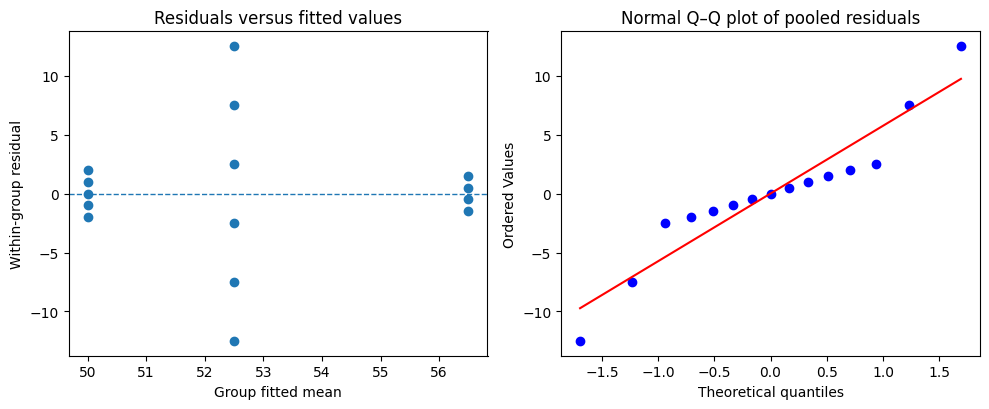

In [10]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

groups = [np.array([48, 51, 50, 49, 52], dtype=float),
          np.array([45, 55, 60, 40, 50, 65], dtype=float),
          np.array([55, 58, 57, 56], dtype=float)]
means = [x.mean() for x in groups]
residuals = np.concatenate([x - x.mean() for x in groups])
fitted = np.concatenate([np.full(len(x), x.mean()) for x in groups])

levene = stats.levene(*groups, center="median")
print(f"Median-centered Levene statistic={levene.statistic:.3f}, "
      f"p={levene.pvalue:.4f}")
print("Sample standard deviations:",
      [round(x.std(ddof=1), 3) for x in groups])

fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
axes[0].scatter(fitted, residuals)
axes[0].axhline(0, linestyle="--", linewidth=1)
axes[0].set(xlabel="Group fitted mean", ylabel="Within-group residual",
            title="Residuals versus fitted values")
stats.probplot(residuals, dist="norm", plot=axes[1])
axes[1].set_title("Normal Q–Q plot of pooled residuals")
fig.tight_layout()
fig.savefig("../../images/anova_residual_diagnostics.png", dpi=170,
            bbox_inches="tight")
plt.show()

## Experiment: recover the ANOVA F-test from ordinary least squares.

In [12]:
import numpy as np
import pandas as pd
from scipy import stats
import statsmodels.formula.api as smf
from statsmodels.stats.anova import anova_lm

A = np.array([6, 8, 7, 9], dtype=float)
B = np.array([10, 12, 11, 13], dtype=float)
group_c = np.array([8, 10, 9, 11], dtype=float)
df = pd.DataFrame({
    "score": np.concatenate([A, B, group_c]),
    "group": np.repeat(["A", "B", "C"], [len(A), len(B), len(group_c)])
})

model = smf.ols("score ~ group", data=df).fit()
print("OLS coefficients:")
print(model.params)
print("\nANOVA table from regression:")
print(anova_lm(model, typ=2))
print(f"Regression overall F = {model.fvalue:.4f}")
print(f"Classical one-way F = {stats.f_oneway(A, B, group_c).statistic:.4f}")

OLS coefficients:
Intercept     7.5
group[T.B]    4.0
group[T.C]    2.0
dtype: float64

ANOVA table from regression:
          sum_sq   df    F    PR(>F)
group       32.0  2.0  9.6  0.005861
Residual    15.0  9.0  NaN       NaN
Regression overall F = 9.6000
Classical one-way F = 9.6000


## Experiment: approximate a permutation p-value for the omnibus F-statistic.

In [13]:
import numpy as np
from scipy import stats

rng = np.random.default_rng(163)

# Original observations from the three training methods.
groups = [
    np.array([6, 8, 7, 9], dtype=float),
    np.array([10, 12, 11, 13], dtype=float),
    np.array([8, 10, 9, 11], dtype=float),
]

# Store the group sizes and collect all observed scores.
lengths = [len(x) for x in groups]
values = np.concatenate(groups)

# Calculate the F-statistic from the original assignment.
F_observed = stats.f_oneway(*groups).statistic

# Number of random reassignments.
B = 9999
exceedances = 0

for _ in range(B):
    # Randomly rearrange all twelve observed scores.
    shuffled = rng.permutation(values)

    # Split the shuffled scores into groups of the original sizes.
    reassigned = np.split(
        shuffled,
        np.cumsum(lengths)[:-1],
    )

    # Calculate the F-statistic for this reassignment.
    F_permuted = stats.f_oneway(*reassigned).statistic

    # Count statistics at least as large as the observed F.
    exceedances += (F_permuted >= F_observed)

# Monte Carlo permutation p-value.
p_mc = (exceedances + 1) / (B + 1)

# Classical ANOVA p-value for comparison.
p_parametric = stats.f.sf(F_observed, 2, 9)

print(f"Observed F-statistic: {F_observed:.4f}")
print(f"Number of permutations: {B}")
print(f"Exceedances: {exceedances}")
print(f"Permutation p-value: {p_mc:.5f}")
print(f"Parametric ANOVA p-value: {p_parametric:.5f}")

Observed F-statistic: 9.6000
Number of permutations: 9999
Exceedances: 77
Permutation p-value: 0.00780
Parametric ANOVA p-value: 0.00586
